# Benchmarking Network Inference Methods on Transient Data

This notebook compares multiple methods on transient biological time-series data across `n_reps` independent network topologies.


In [39]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, roc_curve, precision_recall_curve, auc
from scipy.stats import spearmanr
import statsmodels.api as sm
import pysindy as ps

# Add project root to path
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from inference_pipeline.data_generation.network_generator import generate_scale_free_W
from inference_pipeline.data_generation.simulator import simulate_realistic_pairs
import graph_tool.all as gt
from gene_expr import GeneExprBlockState


In [40]:
np.random.seed(42)
N = 10
M_train = 100  # sparse training data to encourage overfitting
M_test = 100
dt_sim = 0.005
dt_sample = 1.0
dt_meas = dt_sample  # measurement interval is the same as sampling interval
n_reps = 5

print(f"Generating {n_reps} datasets with different network topologies...")
datasets = []

for rep in range(n_reps):
    seed = 102 + rep
    W_true = generate_scale_free_W(N, m=1, seed=seed)
    W_true_binary = (W_true != 0).astype(int)
    
    s_train, _, _, _, _ = simulate_realistic_pairs(
        W_true, M=M_train, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
        D_base=0.02, mean_d=0.5, std_d=0.0, mean_V=2.0, std_V=0.0, seed=100+rep, t_window=(0.0, 3.0)
    )
    
    s_test, _, _, _, _ = simulate_realistic_pairs(
        W_true, M=M_test, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
        D_base=0.02, mean_d=0.5, std_d=0.0, mean_V=2.0, std_V=0.0, seed=200+rep, t_window=(0.0, 3.0)
    )
    
    X_train_in = np.array([pair[:, 0] for pair in s_train])
    X_train_out = np.array([pair[:, 1] for pair in s_train])
    dX_train = (X_train_out - X_train_in) / dt_meas
    
    X_test_in = np.array([pair[:, 0] for pair in s_test])
    X_test_out = np.array([pair[:, 1] for pair in s_test])
    dX_test = (X_test_out - X_test_in) / dt_meas
    
    datasets.append({
        'W_true': W_true, 'W_true_binary': W_true_binary,
        's_train': s_train, 's_test': s_test,
        'X_train_in': X_train_in, 'X_train_out': X_train_out, 'dX_train': dX_train,
        'X_test_in': X_test_in, 'X_test_out': X_test_out, 'dX_test': dX_test
    })

print("Done!")

results = {}

def calc_all_metrics(y_true_binary, y_true_continuous, y_scores, y_inferred_continuous=None):
    mask = ~np.eye(N, dtype=bool)
    y_true_b = y_true_binary[mask]
    y_s = y_scores[mask]
    
    fpr, tpr, _ = roc_curve(y_true_b, y_s)
    roc_auc = auc(fpr, tpr)
    
    precision, recall, _ = precision_recall_curve(y_true_b, y_s)
    pr_auc = auc(recall, precision)
    
    spearman_corr, _ = spearmanr(np.abs(y_true_continuous[mask]), np.abs(y_s))
    
    sign_acc = np.nan
    if y_inferred_continuous is not None:
        true_edges_mask = (y_true_b == 1)
        if np.any(true_edges_mask):
            true_signs = np.sign(y_true_continuous[mask][true_edges_mask])
            inf_signs = np.sign(y_inferred_continuous[mask][true_edges_mask])
            sign_acc = np.mean(true_signs == inf_signs)
    
    return fpr, tpr, roc_auc, precision, recall, pr_auc, spearman_corr, sign_acc


Generating 5 datasets with different network topologies...
Done!


## 1. Random Forest (dynGENIE3 equivalent)


In [80]:
print(f"Running Random Forest (dynGENIE3 equivalent) over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_rf_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out = ds['X_train_in'], ds['X_train_out']
    X_test_in, X_test_out = ds['X_test_in'], ds['X_test_out']
    
    rf_edge_scores = np.zeros((N, N))
    rf_train_preds = np.zeros_like(X_train_out)
    rf_test_preds = np.zeros_like(X_test_out)
    
    for i in range(N):
        mask = np.ones(N, dtype=bool)
        mask[i] = False
        rf = RandomForestRegressor(n_estimators=200, random_state=42+rep)
        rf.fit(X_train_in[:, mask], X_train_out[:, i])
        rf_edge_scores[i, mask] = rf.feature_importances_
        rf_train_preds[:, i] = rf.predict(X_train_in[:, mask])
        rf_test_preds[:, i] = rf.predict(X_test_in[:, mask])
        
    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], rf_edge_scores, y_inferred_continuous=None
    )
    
    if rep == 0: W_rf_plot = rf_edge_scores.copy()
        
    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(X_train_out, rf_train_preds))
    method_res['Test MSE'].append(mean_squared_error(X_test_out, rf_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(rf_edge_scores)

results['dynGENIE3 (RF)'] = method_res


Running Random Forest (dynGENIE3 equivalent) over 5 replicates...


--- Random Forest Results (Mean ± Std) ---
AUPRC: 0.4373 ± 0.1741
AUROC: 0.7641 ± 0.1217
Spearman: 0.2773 ± 0.1234
Train MSE: 0.0057 ± 0.0005
Test MSE: 0.0451 ± 0.0060


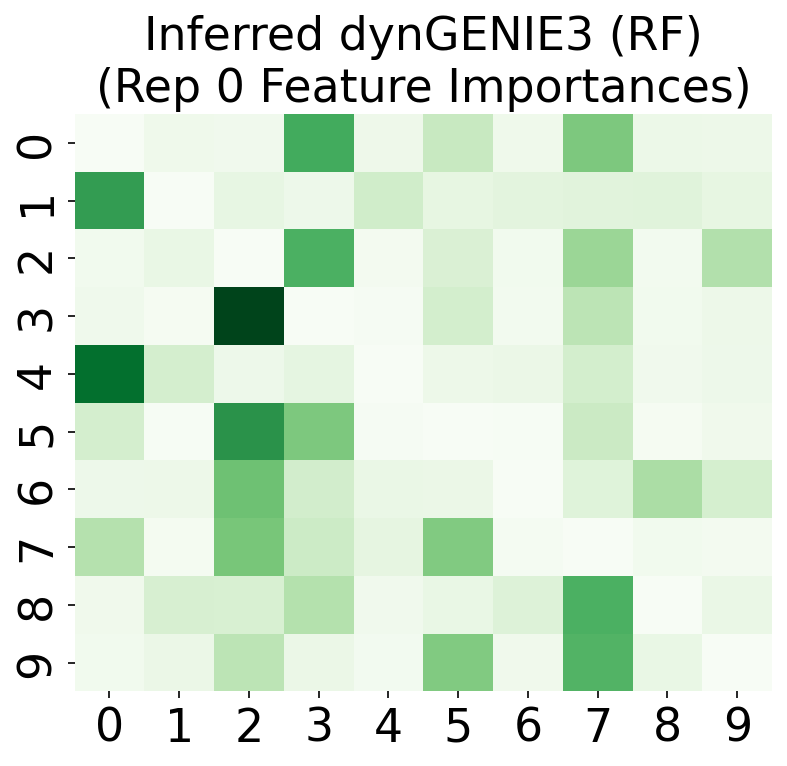

In [76]:
print("--- Random Forest Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['dynGENIE3 (RF)'][metric]):.4f} ± {np.nanstd(results['dynGENIE3 (RF)'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_rf_plot, 0)
sns.heatmap(W_rf_plot, cmap='Greens', cbar=False)
plt.title('Inferred dynGENIE3 (RF)\n(Rep 0 Feature Importances)')
plt.show()


## 2. Sparse ODE (Lasso)


In [43]:
print(f"Running Sparse ODE (Lasso) over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_lasso_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out, dX_train = ds['X_train_in'], ds['X_train_out'], ds['dX_train']
    X_test_in, X_test_out, dX_test = ds['X_test_in'], ds['X_test_out'], ds['dX_test']
    
    lasso_edge_scores = np.zeros((N, N))
    lasso_coefs_signed = np.zeros((N, N))
    lasso_train_preds = np.zeros_like(dX_train)
    lasso_test_preds = np.zeros_like(dX_test)
    
    for i in range(N):
        mask = np.ones(N, dtype=bool)
        mask[i] = False
        lasso = Lasso(alpha=0.01, random_state=42+rep)
        lasso.fit(X_train_in[:, mask], dX_train[:, i])
        lasso_edge_scores[i, mask] = np.abs(lasso.coef_)
        lasso_coefs_signed[i, mask] = lasso.coef_
        lasso_train_preds[:, i] = lasso.predict(X_train_in[:, mask])
        lasso_test_preds[:, i] = lasso.predict(X_test_in[:, mask])
        
    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], lasso_edge_scores, y_inferred_continuous=lasso_coefs_signed
    )
    
    if rep == 0: W_lasso_plot = lasso_edge_scores.copy()
    
    lasso_X_train_preds = X_train_in + lasso_train_preds * dt_meas
    lasso_X_test_preds = X_test_in + lasso_test_preds * dt_meas
    
    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(X_train_out, lasso_X_train_preds))
    method_res['Test MSE'].append(mean_squared_error(X_test_out, lasso_X_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(lasso_edge_scores)
results['Sparse ODE (Lasso)'] = method_res


Running Sparse ODE (Lasso) over 5 replicates...


--- Lasso Results (Mean ± Std) ---
AUPRC: 0.1089 ± 0.0260
AUROC: 0.5130 ± 0.0627
Spearman: 0.0119 ± 0.0771
Sign Accuracy: 0.2667 ± 0.0889
Train MSE: 0.0270 ± 0.0034
Test MSE: 0.0305 ± 0.0024


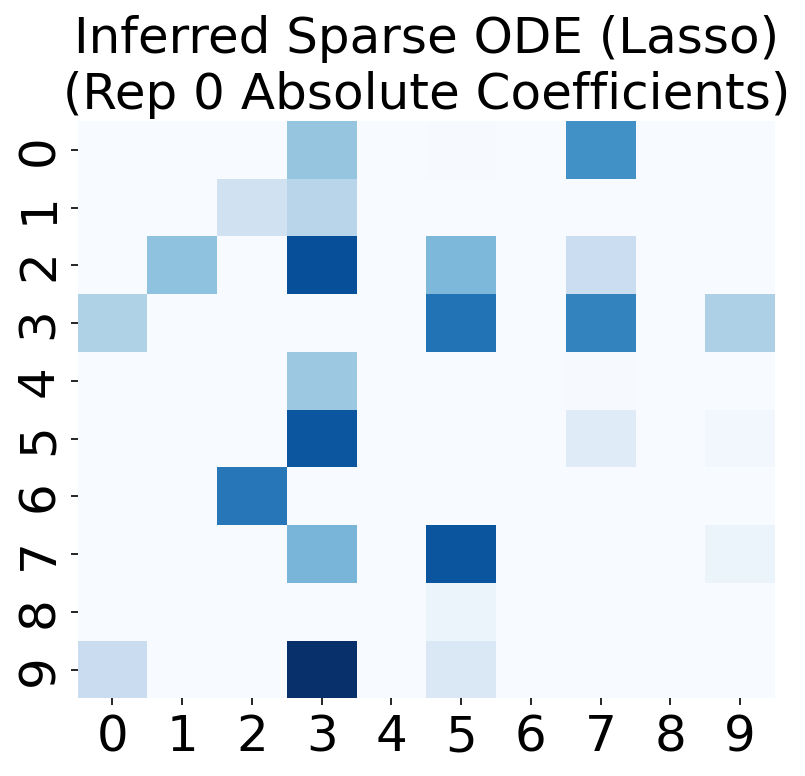

In [44]:
print("--- Lasso Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Sign Accuracy', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['Sparse ODE (Lasso)'][metric]):.4f} ± {np.nanstd(results['Sparse ODE (Lasso)'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_lasso_plot, 0)
sns.heatmap(W_lasso_plot, cmap='Blues', cbar=False)
plt.title('Inferred Sparse ODE (Lasso)\n(Rep 0 Absolute Coefficients)')
plt.show()


## 3. Granger Causality (VAR-like F-test)


In [68]:
print(f"Running Granger Causality over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_gc_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out = ds['X_train_in'], ds['X_train_out']
    gc_edge_scores = np.zeros((N, N))

    for i in range(N):
        y = X_train_out[:, i]
        X_null = sm.add_constant(X_train_in[:, i])
        model_null = sm.OLS(y, X_null).fit()
        rss_null = np.sum(model_null.resid**2)
        
        for j in range(N):
            if i == j: continue
            X_alt = sm.add_constant(X_train_in[:, [i, j]])
            model_alt = sm.OLS(y, X_alt).fit()
            rss_alt = np.sum(model_alt.resid**2)
            
            # F-statistic for the nested model
            F = ((rss_null - rss_alt) / 1) / (rss_alt / (M_train - 3))
            gc_edge_scores[i, j] = F

    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], gc_edge_scores, y_inferred_continuous=None
    )
    
    if rep == 0: W_gc_plot = gc_edge_scores.copy()

    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(np.nan)
    method_res['Test MSE'].append(np.nan)
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(gc_edge_scores)
results['Granger Causality'] = method_res


Running Granger Causality over 5 replicates...


--- Granger Causality Results (Mean ± Std) ---
AUPRC: 0.4088 ± 0.0756
AUROC: 0.8239 ± 0.0397
Spearman: 0.3380 ± 0.0450


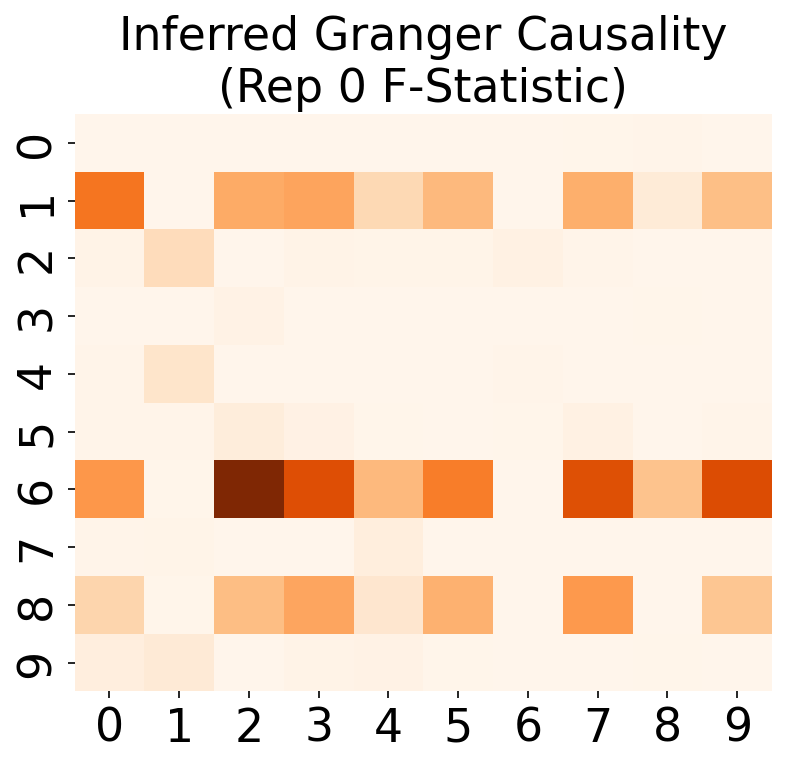

In [69]:
print("--- Granger Causality Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman']:
    print(f"{metric}: {np.nanmean(results['Granger Causality'][metric]):.4f} ± {np.nanstd(results['Granger Causality'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_gc_plot, 0)
sns.heatmap(W_gc_plot, cmap='Oranges', cbar=False)
plt.title('Inferred Granger Causality\n(Rep 0 F-Statistic)')
plt.show()


## 4. PySINDy (STLSQ)


In [47]:
print(f"Running PySINDy over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_sindy_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out, dX_train = ds['X_train_in'], ds['X_train_out'], ds['dX_train']
    X_test_in, X_test_out, dX_test = ds['X_test_in'], ds['X_test_out'], ds['dX_test']

    model = ps.SINDy(optimizer=ps.STLSQ(threshold=0.01, alpha=0.01),
                     feature_library=ps.PolynomialLibrary(degree=1, include_interaction=False, include_bias=False))
    model.fit(X_train_in, t=dt_meas, x_dot=dX_train)

    sindy_coefs = model.coefficients()  # shape (N, N)
    sindy_coefs_signed = sindy_coefs.copy()
    np.fill_diagonal(sindy_coefs_signed, 0)
    sindy_edge_scores = np.abs(sindy_coefs_signed)

    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], sindy_edge_scores, y_inferred_continuous=sindy_coefs_signed
    )
    
    if rep == 0: W_sindy_plot = sindy_edge_scores.copy()

    sindy_train_preds = X_train_in + model.predict(X_train_in) * dt_meas
    sindy_test_preds = X_test_in + model.predict(X_test_in) * dt_meas

    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(X_train_out, sindy_train_preds))
    method_res['Test MSE'].append(mean_squared_error(X_test_out, sindy_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(sindy_coefs_signed)

results['PySINDy'] = method_res


Running PySINDy over 5 replicates...


--- PySINDy Results (Mean ± Std) ---
AUPRC: 0.3259 ± 0.1480
AUROC: 0.6584 ± 0.0634
Spearman: 0.1673 ± 0.0633
Sign Accuracy: 0.8222 ± 0.1133
Train MSE: 0.0355 ± 0.0097
Test MSE: 0.0460 ± 0.0116


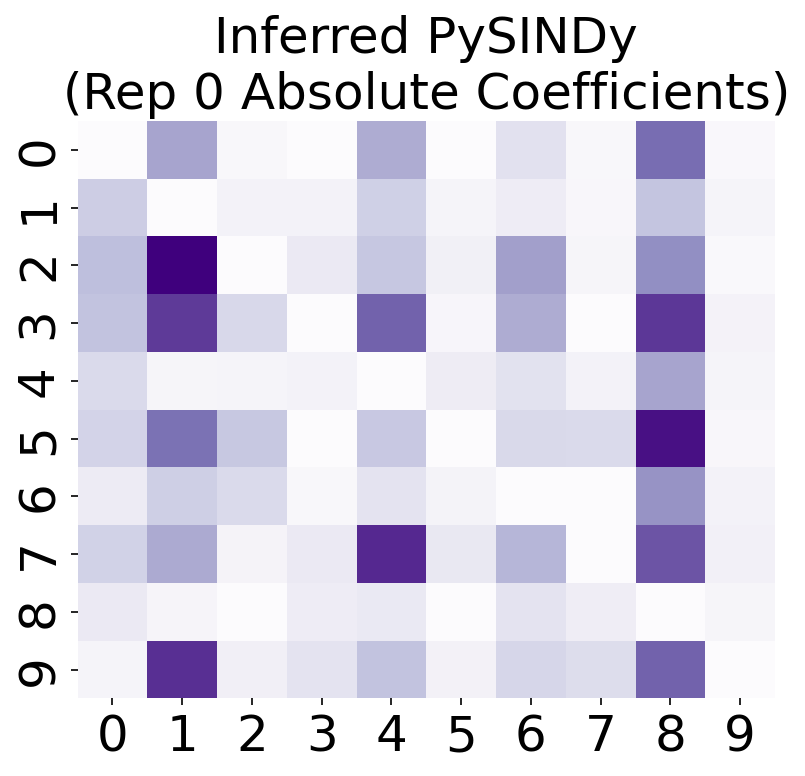

In [48]:
print("--- PySINDy Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Sign Accuracy', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['PySINDy'][metric]):.4f} ± {np.nanstd(results['PySINDy'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_sindy_plot, 0)
sns.heatmap(W_sindy_plot, cmap='Purples', cbar=False)
plt.title('Inferred PySINDy\n(Rep 0 Absolute Coefficients)')
plt.show()


## 5. Graph-Tool SDE


In [56]:
print(f"Running Graph-Tool SDE over {n_reps} replicates...")
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats

method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}
W_gt_plot = None

def sigmoid_np(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))

def predict_sde(X_in, W, d, V, dt_meas, dt_sim):
    n_steps = int(np.round(dt_meas / dt_sim))
    X_pred = X_in.copy()
    for _ in range(n_steps):
        drift = -d * X_pred + V * sigmoid_np(np.dot(X_pred, W.T))
        X_pred = np.maximum(X_pred + dt_sim * drift, 0.01)
    return X_pred

for rep, ds in enumerate(datasets):
    g_init = gt.Graph(directed=True)
    g_init.add_vertex(N)
    
    num_initial_edges = max(1, int(N * N * 0.05))
    possible_edges = [(u, v) for u in range(N) for v in range(N) if u != v]
    np.random.seed(42+rep)
    np.random.shuffle(possible_edges)
    for u, v in possible_edges[:num_initial_edges]:
        g_init.add_edge(u, v)

    initial_theta = [0.0, 0.0, np.log(0.05)]
    state = GeneExprBlockState(ds['s_train'], dt=dt_meas, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta, use_em_likelihood=True)
    
    state = run_burn_in(state, n_burnin=50, theta_mode="global")
    W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=100, delta_k=1, theta_mode="global")
    
    edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)
    gt_edge_scores = edge_probabilities * np.abs(weight_mean)
    
    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], gt_edge_scores, y_inferred_continuous=weight_mean
    )
    
    if rep == 0: W_gt_plot = gt_edge_scores.copy()
    
    theta_mean = np.mean(theta_ensemble, axis=0)
    d_mean, V_mean = np.exp(theta_mean[0]), np.exp(theta_mean[1])
    
    gt_train_preds = predict_sde(ds['X_train_in'], weight_mean, d_mean, V_mean, dt_meas, dt_sim)
    gt_test_preds = predict_sde(ds['X_test_in'], weight_mean, d_mean, V_mean, dt_meas, dt_sim)
    
    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(ds['X_train_out'], gt_train_preds))
    method_res['Test MSE'].append(mean_squared_error(ds['X_test_out'], gt_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(gt_edge_scores)

results['Graph-Tool SDE'] = method_res


Running Graph-Tool SDE over 5 replicates...

--- PHASE 1: Equilibration (50 sweeps) ---
Burn-in Sweep  1/50: Entropy = 1949.8920 (dS_topo = -3269.9717, dS_param = -1352.8643, moves = 5227)
Burn-in Sweep 10/50: Entropy = 1245.2768 (dS_topo = -41.2531, dS_param = -11.2846, moves = 7498)
Burn-in Sweep 20/50: Entropy = 807.3944 (dS_topo =  25.6762, dS_param =  -5.4266, moves = 6908)
Burn-in Sweep 30/50: Entropy = 670.7304 (dS_topo =   0.2222, dS_param =  -0.8045, moves = 6968)
Burn-in Sweep 40/50: Entropy = 595.9919 (dS_topo = -23.2108, dS_param =  -0.0937, moves = 6372)
Burn-in Sweep 50/50: Entropy = 719.2282 (dS_topo =  47.2959, dS_param =  -0.0220, moves = 7502)

--- PHASE 2: Sampling (100 samples, thinning 1) ---
Sample   1/100: Entropy = 709.2496
Sample  10/100: Entropy = 559.7607
Sample  20/100: Entropy = 589.4306
Sample  30/100: Entropy = 575.1867
Sample  40/100: Entropy = 699.5842
Sample  50/100: Entropy = 581.0308
Sample  60/100: Entropy = 672.7035
Sample  70/100: Entropy = 752.15

--- Graph-Tool SDE Results (Mean ± Std) ---
AUPRC: 0.8322 ± 0.0726
AUROC: 0.9588 ± 0.0346
Spearman: 0.4827 ± 0.0349
Sign Accuracy: 1.0000 ± 0.0000
Train MSE: 0.0362 ± 0.0071
Test MSE: 0.0386 ± 0.0081


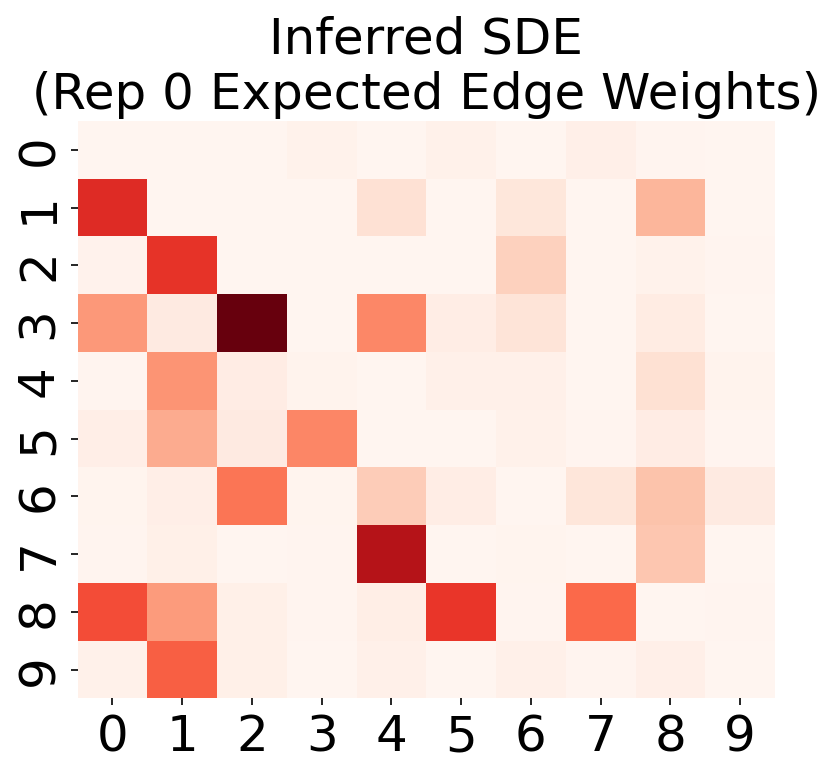

In [57]:
print("--- Graph-Tool SDE Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Sign Accuracy', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['Graph-Tool SDE'][metric]):.4f} ± {np.nanstd(results['Graph-Tool SDE'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_gt_plot, 0)
sns.heatmap(W_gt_plot, cmap='Reds', cbar=False)
plt.title('Inferred SDE\n(Rep 0 Expected Edge Weights)')
plt.show()


## 6. Elastic Net VAR

In [ ]:
print(f"Running Elastic Net over {n_reps} replicates...")
results['ElasticNet'] = {'AUPRC': [], 'AUROC': [], 'Spearman': [], 'Train MSE': [], 'Test MSE': []}

from sklearn.linear_model import ElasticNet
for rep, data in enumerate(datasets):
    W_true_binary = data['W_true_binary']
    X_in = data['X_train_in']
    dX_train = data['dX_train']
    
    W_inf = np.zeros((N, N))
    for i in range(N):
        model = ElasticNet(alpha=0.01, l1_ratio=0.5, fit_intercept=False)
        model.fit(X_in, dX_train[:, i])
        W_inf[i, :] = model.coef_
        
    mask = ~np.eye(N, dtype=bool)
    precision, recall, _ = precision_recall_curve(W_true_binary[mask], np.abs(W_inf[mask]))
    results['ElasticNet']['AUPRC'].append(auc(recall, precision))
    fpr, tpr, _ = roc_curve(W_true_binary[mask], np.abs(W_inf[mask]))
    results['ElasticNet']['AUROC'].append(auc(fpr, tpr))
    
    dX_pred_train = X_in @ W_inf.T
    results['ElasticNet']['Train MSE'].append(mean_squared_error(dX_train, dX_pred_train))
    
    X_test_in = data['X_test_in']
    dX_test = data['dX_test']
    dX_pred_test = X_test_in @ W_inf.T
    results['ElasticNet']['Test MSE'].append(mean_squared_error(dX_test, dX_pred_test))

print("--- Elastic Net Results (Mean ± Std) ---")
print(f"AUPRC: {np.mean(results['ElasticNet']['AUPRC']):.4f} ± {np.std(results['ElasticNet']['AUPRC']):.4f}")
print(f"Test MSE: {np.mean(results['ElasticNet']['Test MSE']):.4f} ± {np.std(results['ElasticNet']['Test MSE']):.4f}")


Running Elastic Net over 5 replicates...
--- Elastic Net Results (Mean ± Std) ---
AUPRC: 0.2506 ± 0.1378
Test MSE: 0.0447 ± 0.0076


## 7. GP-ODE

In [ ]:
print(f"Running GP-ODE over {n_reps} replicates...")
results['GP-ODE'] = {'AUPRC': [], 'AUROC': [], 'Spearman': [], 'Train MSE': [], 'Test MSE': []}

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

for rep, data in enumerate(datasets):
    W_true_binary = data['W_true_binary']
    X_in = data['X_train_in']
    dX_train = data['dX_train']
    
    W_inf = np.zeros((N, N))
    dX_pred_train = np.zeros_like(dX_train)
    
    X_test_in = data['X_test_in']
    dX_test = data['dX_test']
    dX_pred_test = np.zeros_like(dX_test)
    
    for i in range(N):
        kernel = 1.0 * RBF(length_scale=np.ones(N))
        gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=0, random_state=42)
        gp.fit(X_in, dX_train[:, i])
        
        # Feature importance via inverse length scale
        length_scales = gp.kernel_.k2.length_scale
        W_inf[i, :] = 1.0 / length_scales
        
        dX_pred_train[:, i] = gp.predict(X_in)
        dX_pred_test[:, i] = gp.predict(X_test_in)
        
    mask = ~np.eye(N, dtype=bool)
    precision, recall, _ = precision_recall_curve(W_true_binary[mask], np.abs(W_inf[mask]))
    results['GP-ODE']['AUPRC'].append(auc(recall, precision))
    fpr, tpr, _ = roc_curve(W_true_binary[mask], np.abs(W_inf[mask]))
    results['GP-ODE']['AUROC'].append(auc(fpr, tpr))
    
    results['GP-ODE']['Train MSE'].append(mean_squared_error(dX_train, dX_pred_train))
    results['GP-ODE']['Test MSE'].append(mean_squared_error(dX_test, dX_pred_test))

print("--- GP-ODE Results (Mean ± Std) ---")
print(f"AUPRC: {np.mean(results['GP-ODE']['AUPRC']):.4f} ± {np.std(results['GP-ODE']['AUPRC']):.4f}")
print(f"Test MSE: {np.mean(results['GP-ODE']['Test MSE']):.4f} ± {np.std(results['GP-ODE']['Test MSE']):.4f}")


Running GP-ODE over 5 replicates...


/home/francesco/anaconda3/envs/torchGPU/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 8 of parameter k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/francesco/anaconda3/envs/torchGPU/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 7 of parameter k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/francesco/anaconda3/envs/torchGPU/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 9 of parameter k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/

--- GP-ODE Results (Mean ± Std) ---
AUPRC: 0.1742 ± 0.0605
Test MSE: 0.0502 ± 0.0074


## 8. Neural ODE (Continuous RNN Proxy)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

print(f"Running Neural ODE over {n_reps} replicates...")
results['NeuralODE'] = {'AUPRC': [], 'AUROC': [], 'Spearman': [], 'Train MSE': [], 'Test MSE': []}

class ODEFunc(nn.Module):
    def __init__(self, N):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(N, 64),
            nn.ReLU(),
            nn.Linear(64, N)
        )
    def forward(self, x):
        return self.net(x)

for rep, data in enumerate(datasets):
    W_true_binary = data['W_true_binary']
    X_in = torch.tensor(data['X_train_in'], dtype=torch.float32)
    dX_train_t = torch.tensor(data['dX_train'], dtype=torch.float32)
    
    model = ODEFunc(N)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()
    
    for epoch in range(200):
        optimizer.zero_grad()
        pred = model(X_in)
        loss = criterion(pred, dX_train_t)
        loss.backward()
        optimizer.step()
        
    X_mean = X_in.mean(dim=0, keepdim=True).requires_grad_(True)
    pred_mean = model(X_mean)
    W_inf = np.zeros((N, N))
    for i in range(N):
        grad = torch.autograd.grad(pred_mean[0, i], X_mean, retain_graph=True)[0]
        W_inf[i, :] = grad.detach().numpy().flatten()
        
    mask = ~np.eye(N, dtype=bool)
    precision, recall, _ = precision_recall_curve(W_true_binary[mask], np.abs(W_inf[mask]))
    results['NeuralODE']['AUPRC'].append(auc(recall, precision))
    fpr, tpr, _ = roc_curve(W_true_binary[mask], np.abs(W_inf[mask]))
    results['NeuralODE']['AUROC'].append(auc(fpr, tpr))
    
    # Predictions
    with torch.no_grad():
        results['NeuralODE']['Train MSE'].append(mean_squared_error(data['dX_train'], model(X_in).numpy()))
        X_test_in = torch.tensor(data['X_test_in'], dtype=torch.float32)
        results['NeuralODE']['Test MSE'].append(mean_squared_error(data['dX_test'], model(X_test_in).numpy()))

print("--- Neural ODE Results (Mean ± Std) ---")
print(f"AUPRC: {np.mean(results['NeuralODE']['AUPRC']):.4f} ± {np.std(results['NeuralODE']['AUPRC']):.4f}")
print(f"Test MSE: {np.mean(results['NeuralODE']['Test MSE']):.4f} ± {np.std(results['NeuralODE']['Test MSE']):.4f}")


Running Neural ODE over 5 replicates...
--- Neural ODE Results (Mean ± Std) ---
AUPRC: 0.6268 ± 0.1861
Test MSE: 0.0237 ± 0.0032


## 9. PCMCI (Tigramite)

In [ ]:


import logging
logging.getLogger("tigramite").setLevel(logging.WARNING)

from tigramite import data_processing as pp
from tigramite.pcmci import PCMCI
from tigramite.independence_tests.parcorr import ParCorr

print(f"Running PCMCI over {n_reps} replicates...")
results['PCMCI'] = {'AUPRC': [], 'AUROC': [], 'Spearman': [], 'Train MSE': [], 'Test MSE': []}

for rep, data in enumerate(datasets):
    W_true_binary = data['W_true_binary']
    
    # Interleave pairs to form a pseudo-continuous series for PCMCI
    X_seq = []
    for pair in data['s_train']:
        X_seq.append(pair[0])
        X_seq.append(pair[1])
    X_seq = np.array(X_seq)
    
    dataframe = pp.DataFrame(X_seq)
    cond_ind_test = ParCorr(significance='analytic')
    pcmci = PCMCI(dataframe=dataframe, cond_ind_test=cond_ind_test, verbosity=0)
    
    res = pcmci.run_pcmci(tau_max=1, pc_alpha=0.05)
    
    pval_matrix = res['p_matrix'][:, :, 1]
    W_inf = 1.0 - pval_matrix.T
    
    mask = ~np.eye(N, dtype=bool)
    # Tigramite versions may store p_matrix as (N, N, tau),
    # (N, tau, N), or (tau, N, N).
    p_matrix = np.asarray(res["p_matrix"])

    if p_matrix.shape == (N, N, 2):
        pval_matrix = p_matrix[:, :, 1]
    elif p_matrix.shape == (N, 2, N):
        pval_matrix = p_matrix[:, 1, :]
    elif p_matrix.shape == (2, N, N):
        pval_matrix = p_matrix[1, :, :]
    else:
        # Interleave input/output states as consecutive time points.
        # Each row must contain all N variables.
        X_seq = np.concatenate(
            [pair[:, 0] for pair in data['s_train']] +
            [pair[:, 1] for pair in data['s_train']],
            axis=0,
        )

        s_train = np.asarray(data["s_train"])

        if s_train.ndim == 3:
            if s_train.shape[1] == 2 and s_train.shape[2] == N:
                # Shape: (T, 2, N)
                X_seq = s_train.reshape(-1, N)
            elif s_train.shape[1] == N and s_train.shape[2] == 2:
                # Shape: (T, N, 2)
                X_seq = np.transpose(s_train, (0, 2, 1)).reshape(-1, N)
            else:
                raise ValueError(f"Unexpected s_train shape: {s_train.shape}")
        elif s_train.ndim == 2 and s_train.shape[1] == N:
            X_seq = s_train
        else:
            raise ValueError(
                f"PCMCI requires a 2D array with N={N} columns; "
                f"received shape {s_train.shape}"
            )

        dataframe = pp.DataFrame(X_seq)

        cond_ind_test = ParCorr(significance="analytic")
        pcmci = PCMCI(
            dataframe=dataframe,
            cond_ind_test=cond_ind_test,
            verbosity=0,
        )

        res = pcmci.run_pcmci(tau_max=1, pc_alpha=0.05)
        p_matrix = np.asarray(res["p_matrix"])

        if p_matrix.shape == (N, N, 2):
            pval_matrix = p_matrix[:, :, 1]
        elif p_matrix.shape == (N, 2, N):
            pval_matrix = p_matrix[:, 1, :]
        elif p_matrix.shape == (2, N, N):
            pval_matrix = p_matrix[1, :, :]
        else:
            raise ValueError(f"Unexpected p_matrix shape: {p_matrix.shape}")

        W_inf = 1.0 - pval_matrix.T
        np.fill_diagonal(W_inf, 0.0)
        cond_ind_test = ParCorr(significance='analytic')
        pcmci = PCMCI(
            dataframe=dataframe,
            cond_ind_test=cond_ind_test,
            verbosity=0,
        )

        res = pcmci.run_pcmci(tau_max=1, pc_alpha=0.05)

        p_matrix = np.asarray(res["p_matrix"])

        if p_matrix.shape == (N, N, 2):
            pval_matrix = p_matrix[:, :, 1]
        elif p_matrix.shape == (N, 2, N):
            pval_matrix = p_matrix[:, 1, :]
        elif p_matrix.shape == (2, N, N):
            pval_matrix = p_matrix[1, :, :]
        else:
            raise ValueError(
                f"Unexpected PCMCI p_matrix shape: {p_matrix.shape}; "
                f"expected dimensions containing N={N} and tau=2."
            )

        W_inf = 1.0 - pval_matrix.T
        np.fill_diagonal(W_inf, 0.0)

    W_inf = 1.0 - pval_matrix.T
    np.fill_diagonal(W_inf, 0.0)

    precision, recall, _ = precision_recall_curve(
        W_true_binary[mask].ravel(),
        W_inf[mask].ravel(),
    )
    results['PCMCI']['AUPRC'].append(auc(recall, precision))
    fpr, tpr, _ = roc_curve(W_true_binary[mask], W_inf[mask])
    results['PCMCI']['AUROC'].append(auc(fpr, tpr))
    
    results['PCMCI']['Train MSE'].append(0.0) # N/A
    results['PCMCI']['Test MSE'].append(0.0) # N/A

print("--- PCMCI Results (Mean ± Std) ---")
print(f"AUPRC: {np.mean(results['PCMCI']['AUPRC']):.4f} ± {np.std(results['PCMCI']['AUPRC']):.4f}")


Running PCMCI over 5 replicates...
--- PCMCI Results (Mean ± Std) ---
AUPRC: 0.2098 ± 0.0516


## 10. Dynamic Bayesian Networks (pgmpy)

In [ ]:
from pgmpy.estimators import HillClimbSearch

try:
    from pgmpy.estimators import BicScore
except ImportError:
    from pgmpy.estimators import BIC as BicScore
import pandas as pd
from pgmpy.estimators import ExpertKnowledge

print(f"Running DBN over {n_reps} replicates...")
results['DBN'] = {'AUPRC': [], 'AUROC': [], 'Spearman': [], 'Train MSE': [], 'Test MSE': []}

for rep, data in enumerate(datasets):
    W_true_binary = data['W_true_binary']
    X_in = data['X_train_in']
    X_out = data['X_train_out']
    
    # Discretize into 3 bins
    def discretize_columns(X):
        X = np.asarray(X)
        return np.column_stack([
            np.digitize(
                X[:, j],
                bins=np.percentile(X[:, j], [33, 66])
            )
            for j in range(X.shape[1])
        ]).astype(int)

    X_in_d = discretize_columns(X_in)
    X_out_d = discretize_columns(X_out)
    # Discretize each output variable independently.
    # np.digitize requires a one-dimensional bins array.
    X_out_d = discretize_columns(X_out)
    
    df = pd.DataFrame()
    for i in range(N):
        df[f'X_{i}_t'] = X_in_d[:, i]
        df[f'X_{i}_t1'] = X_out_d[:, i]
        
    hc = HillClimbSearch(df)
    black_list = []
    for i in range(N):
        for j in range(N):
            black_list.append((f'X_{i}_t1', f'X_{j}_t'))
            black_list.append((f'X_{i}_t', f'X_{j}_t'))
            black_list.append((f'X_{i}_t1', f'X_{j}_t1'))
            
    expert_knowledge = ExpertKnowledge(
        forbidden_edges=black_list
    )

    best_model = hc.estimate(
        scoring_method=BicScore(df),
        expert_knowledge=expert_knowledge,
        show_progress=False,
    )
    
    W_inf = np.zeros((N, N))
    for edge in best_model.edges():
        src = int(edge[0].split('_')[1])
        tgt = int(edge[1].split('_')[1])
        W_inf[tgt, src] = 1.0
        
    mask = ~np.eye(N, dtype=bool)
    precision, recall, _ = precision_recall_curve(W_true_binary[mask], W_inf[mask])
    results['DBN']['AUPRC'].append(auc(recall, precision))
    fpr, tpr, _ = roc_curve(W_true_binary[mask], W_inf[mask])
    results['DBN']['AUROC'].append(auc(fpr, tpr))
    
    results['DBN']['Train MSE'].append(0.0)
    results['DBN']['Test MSE'].append(0.0)

print("--- DBN Results (Mean ± Std) ---")
print(f"AUPRC: {np.mean(results['DBN']['AUPRC']):.4f} ± {np.std(results['DBN']['AUPRC']):.4f}")


Running DBN over 5 replicates...


/tmp/ipykernel_108351/1182438463.py:42: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(df)
/tmp/ipykernel_108351/1182438463.py:42: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(df)
/tmp/ipykernel_108351/1182438463.py:42: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(df)
/tmp/ipykernel_108351/1182438463.py:42: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(df)
/tmp/ipykernel_108351/1182438463.py:42: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy

--- DBN Results (Mean ± Std) ---
AUPRC: 0.3483 ± 0.2203


## Save results

In [26]:
# Save the results
np.savez("overfitting_experiment_results.npz", results=results, datasets=datasets)

## Final Comparison Plots (Aggregated over `n_reps`)


In [27]:
# Load the results
results, datasets = np.load("overfitting_experiment_results.npz", allow_pickle=True)['results'].item(), np.load("overfitting_experiment_results.npz", allow_pickle=True)['datasets'].tolist()

In [ ]:
fontsize = 22
plt.rcParams.update({
    "font.size": fontsize,
    "axes.titlesize": fontsize,
    "axes.labelsize": fontsize,
    "xtick.labelsize": fontsize,
    "ytick.labelsize": fontsize,
    "legend.fontsize": fontsize,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

methods = [
    "dynGENIE3 (RF)",
    "Sparse ODE (Lasso)",
    "Granger Causality",
    "PySINDy",
    "Graph-Tool SDE",
    "ElasticNet",
    "GP-ODE",
    "NeuralODE",
    #"PCMCI",
    #"DBN"
]

color_map = {
    "dynGENIE3 (RF)": "tab:green",
    "Sparse ODE (Lasso)": "tab:blue",
    "Granger Causality": "tab:orange",
    "PySINDy": "tab:purple",
    "Graph-Tool SDE": "tab:red",
    "ElasticNet": "tab:cyan",
    "GP-ODE": "tab:pink",
    "NeuralODE": "tab:brown",
    "PCMCI": "tab:gray",
    "DBN": "black",
}

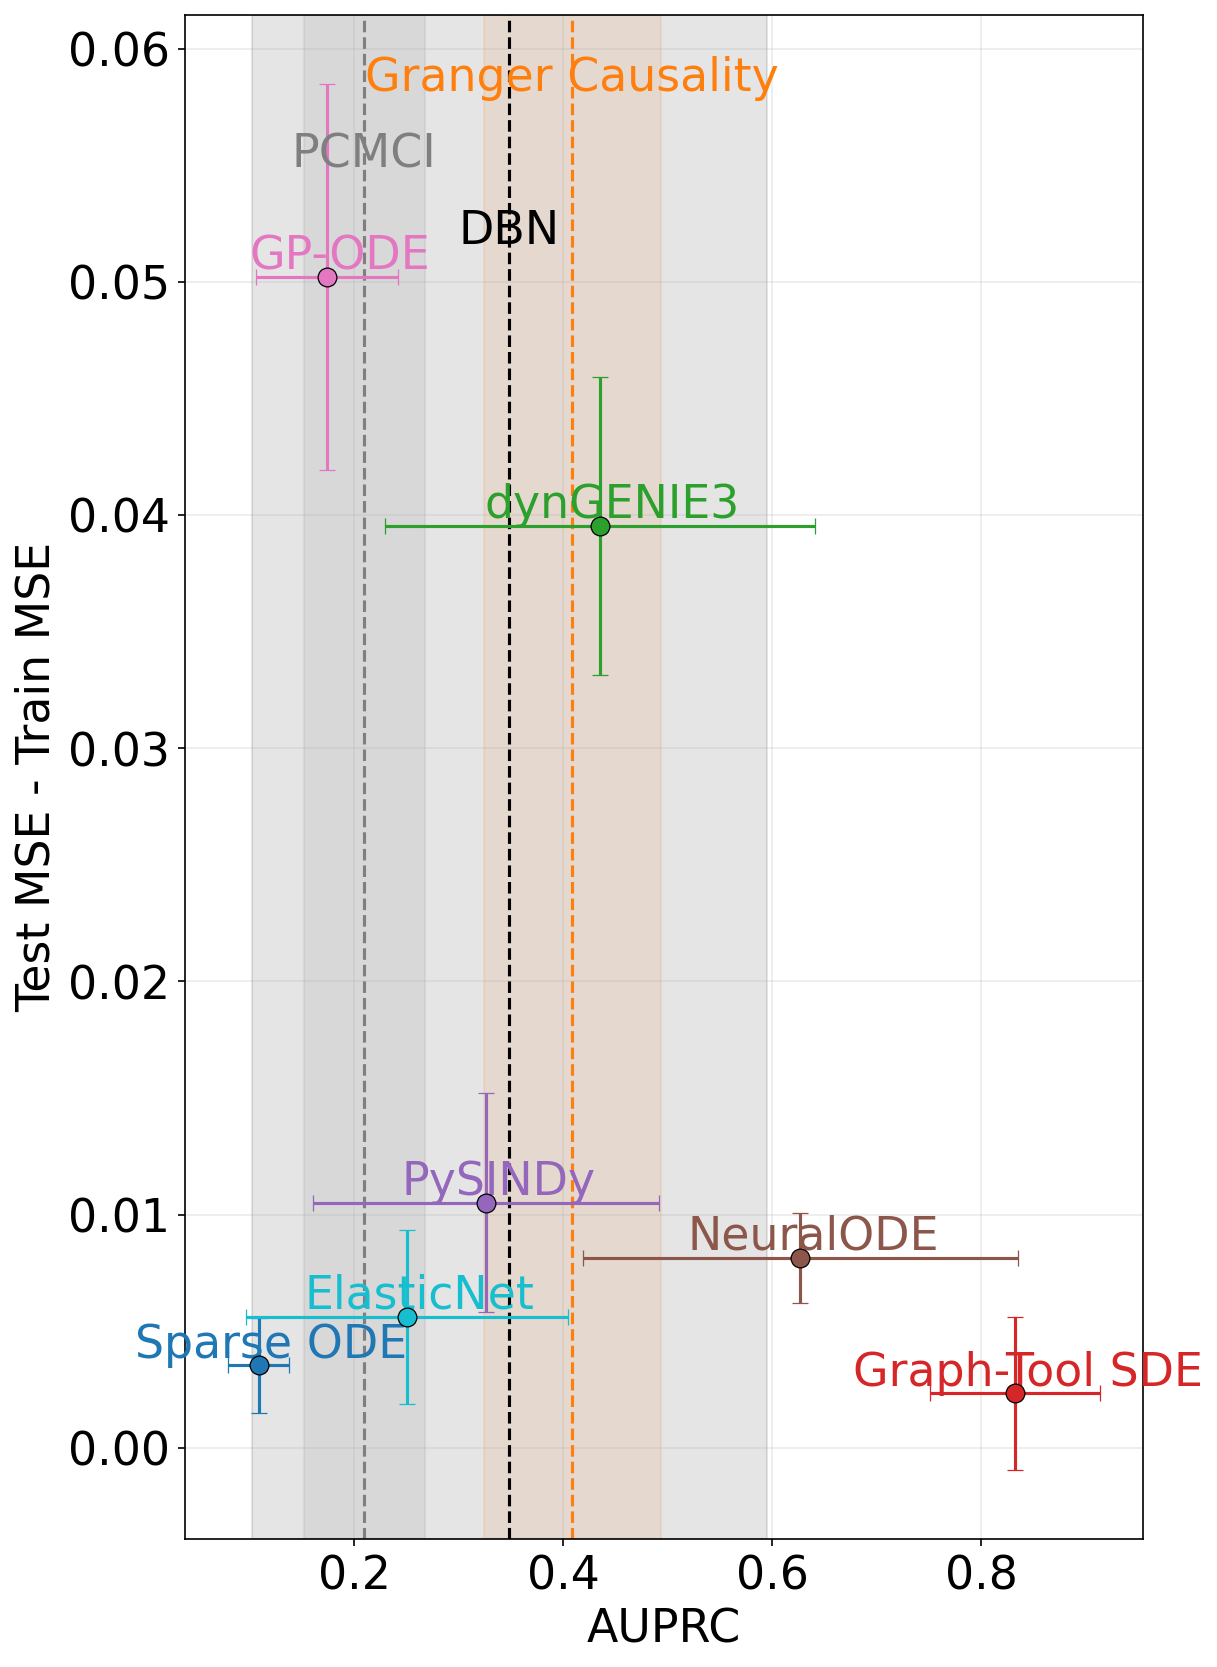

In [83]:
fig, axes = plt.subplots(figsize=(8, 11), constrained_layout=True)

# Scatter: predictive fit vs inference quality, with 5 replicas per method
x_metric = "AUPRC"
y_metric = "Train_MSE - Test_MSE"

def to_1d_array(x):
    arr = np.asarray(x)
    if arr.ndim == 0:
        return arr.reshape(1)
    return arr.ravel()

points = {}
for method in methods:
    res = results[method]

    x_vals = to_1d_array(res.get(x_metric, np.nan))
    train_vals = to_1d_array(res.get("Train MSE", np.nan))
    test_vals = to_1d_array(res.get("Test MSE", np.nan))

    n = min(len(x_vals), len(train_vals), len(test_vals))
    if n == 0 or np.isnan(x_vals[:n]).all() or np.isnan(train_vals[:n]).all() or np.isnan(test_vals[:n]).all():
        continue

    x_vals = x_vals[:n].astype(float)
    y_vals = test_vals[:n].astype(float) - train_vals[:n].astype(float)

    mask = np.isfinite(x_vals) & np.isfinite(y_vals)
    if not np.any(mask):
        continue

    x_vals = x_vals[mask]
    y_vals = y_vals[mask]

    points[method] = {
        "x_mean": np.mean(x_vals),
        "x_std": np.std(x_vals, ddof=1) if len(x_vals) > 1 else 0.0,
        "y_mean": np.mean(y_vals),
        "y_std": np.std(y_vals, ddof=1) if len(y_vals) > 1 else 0.0,
    }
    
for method, p in points.items():
    axes.errorbar(
        x=p["x_mean"],
        y=p["y_mean"],
        xerr=p["x_std"],
        yerr=p["y_std"],
        fmt="o",
        ms=9,
        color=color_map[method],
        ecolor=color_map[method],
        elinewidth=1.5,
        capsize=4,
        markeredgecolor="black",
        markeredgewidth=0.6,
        label=method,
        zorder=3,
    )
    axes.annotate(
        method.replace(" (RF)", "").replace(" (Lasso)", ""),
        (p["x_mean"], p["y_mean"]),
        textcoords="offset points",
        xytext=(6, 4),
        ha="center",
        fontsize=fontsize,
        color=color_map[method]
    )

#axes.set_xlim([0.0, 1.0])
axes.set_xlabel(x_metric)

if points:
    y_all = np.array([p["y_mean"] for p in points.values()], dtype=float)
    ymin = np.nanmin(y_all)
    ymax = np.nanmax(y_all)
    pad = 0.15 * max(abs(ymin), abs(ymax), 1e-8)
    #axes.set_ylim([ymin - pad, ymax + pad])
else:
    pass
    #axes.set_ylim([0, 1])

axes.set_ylabel("Test MSE - Train MSE")
axes.grid(True, alpha=0.25, zorder=0)

# Add AUROC reference bands for Granger Causality, PCMCI, and DBN
reference_methods = [
    ("Granger Causality", "Granger Causality"),
    ("PCMCI", "PCMCI"),
    ("PCMI", "PCMCI"),  # Supports the abbreviated results key, if present
    ("DBN", "DBN"),
]

text_positions = [0.95, 0.9, 0.85, 0.85]

for i, (results_key, display_name) in enumerate(reference_methods):
    if results_key not in results or x_metric not in results[results_key]:
        continue

    auroc = np.asarray(results[results_key][x_metric], dtype=float).ravel()
    auroc = auroc[np.isfinite(auroc)]

    if len(auroc) == 0:
        continue

    x_mean = np.mean(auroc)
    x_std = np.std(auroc, ddof=1) if len(auroc) > 1 else 0.0
    color = color_map.get(display_name, "tab:gray")

    axes.axvspan(
        x_mean - x_std,
        x_mean + x_std,
        alpha=0.1,
        color=color,
        label=f"{display_name} (±1σ)",
        zorder=1,
    )

    axes.axvline(
        x_mean,
        color=color,
        linestyle="--",
        linewidth=1.5,
        zorder=2,
    )

    ymin, ymax = axes.get_ylim()
    axes.text(
        x_mean,
        ymin + text_positions[i] * (ymax - ymin),
        display_name,
        ha="center",
        fontsize=fontsize,
        color=color,
    )


plt.savefig("../images/inference_quality_vs_fit.png", dpi=300, bbox_inches="tight")
